### Dataset : UCI Heart Disease Dataset

# 0. Data Import

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                              precision_score, recall_score, f1_score, roc_curve, auc)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
RANDOM_STATE = 42

In [ ]:
# upload file
from google.colab import files

uploaded = files.upload()

Saving processed.cleveland.data to processed.cleveland (3).data


In [ ]:
columns = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
           "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

df = pd.read_csv("processed.cleveland.data", header=None, names=columns)
print(df.shape)
df

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45.0,1.0,1.0,110.0,264.0,0.0,0.0,132.0,0.0,1.2,2.0,0.0,7.0,1
299,68.0,1.0,4.0,144.0,193.0,1.0,0.0,141.0,0.0,3.4,2.0,2.0,7.0,2
300,57.0,1.0,4.0,130.0,131.0,0.0,0.0,115.0,1.0,1.2,2.0,1.0,7.0,3
301,57.0,0.0,2.0,130.0,236.0,0.0,2.0,174.0,0.0,0.0,2.0,1.0,3.0,1


### Target variable

Since the num is a categorical variable withe severity level (0 = no disease, 1-4: increasing severity).

Since the question asked to predict whether a patient has heart disease based on medical attributes, I created a variable called "target" that binarizes the target variable for the classification task ; taget 1 if num > 0 else 0

In [ ]:
df["target"] = (df["num"] > 0).astype(int)
df = df.drop(columns=["num"])

print(df["target"].value_counts())

target
0    164
1    139
Name: count, dtype: int64


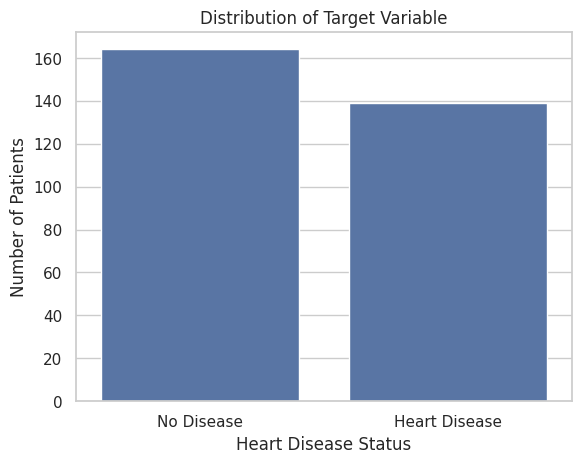

In [ ]:
sns.countplot(x="target", data = df)
plt.title("Distribution of Target Variable")
plt.xlabel('Heart Disease Status')
plt.ylabel('Number of Patients')
plt.xticks([0, 1], ['No Disease', 'Heart Disease'])
plt.show()

# 1. Data Cleaning

### a. Handle missing values (imputation, dropping, or flagging).

The UCI documentation stores missing values as "?" rather than a native NaN

In [ ]:
#missing_value
df = df.replace("?", np.nan)
df = df.apply(pd.to_numeric)

print(df.isna().sum()[df.isna().sum() > 0])

ca      4
thal    2
dtype: int64


Only two columns have missing values: ca (number of major vessels (0-3) colored by flourosopy, 4 missing) and thal (thalassemia test result, 2 missing)

In [ ]:
# check whether missingness correlates with the target
missing_mask = df["ca"].isna() | df["thal"].isna()

print(df[missing_mask])

print("Disease rate when ca/thal missing: ", (df.loc[missing_mask, "target"] > 0).mean().round(3))
print("Disease rate when ca/thal not missing: ", (df.loc[~missing_mask, "target"] > 0).mean().round(3))

      age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
87   53.0  0.0  3.0     128.0  216.0  0.0      2.0    115.0    0.0      0.0   
166  52.0  1.0  3.0     138.0  223.0  0.0      0.0    169.0    0.0      0.0   
192  43.0  1.0  4.0     132.0  247.0  1.0      2.0    143.0    1.0      0.1   
266  52.0  1.0  4.0     128.0  204.0  1.0      0.0    156.0    1.0      1.0   
287  58.0  1.0  2.0     125.0  220.0  0.0      0.0    144.0    0.0      0.4   
302  38.0  1.0  3.0     138.0  175.0  0.0      0.0    173.0    0.0      0.0   

     slope   ca  thal  target  
87     1.0  0.0   NaN       0  
166    1.0  NaN   3.0       0  
192    2.0  NaN   7.0       1  
266    2.0  0.0   NaN       1  
287    2.0  NaN   7.0       0  
302    1.0  NaN   3.0       0  
Disease rate when ca/thal missing:  0.333
Disease rate when ca/thal not missing:  0.461


I imputed them in the section c after the train/test data split to avoid any data leakage.

### b. Address noisy or inconsistent values.



In [ ]:
# Categorical variables except the target variable (num)
cat_cols = ['sex', 'fbs','thal', 'cp', 'restecg','slope','ca']

# value_counts for each columns
for col in cat_cols:
    print(df[col].value_counts(dropna=False))
    print("-" * 30)

# unique values for each columns
for col in cat_cols:
    print(f"{col}: {df[col].unique()}")

sex
1.0    206
0.0     97
Name: count, dtype: int64
------------------------------
fbs
0.0    258
1.0     45
Name: count, dtype: int64
------------------------------
thal
3.0    166
7.0    117
6.0     18
NaN      2
Name: count, dtype: int64
------------------------------
cp
4.0    144
3.0     86
2.0     50
1.0     23
Name: count, dtype: int64
------------------------------
restecg
0.0    151
2.0    148
1.0      4
Name: count, dtype: int64
------------------------------
slope
1.0    142
2.0    140
3.0     21
Name: count, dtype: int64
------------------------------
ca
0.0    176
1.0     65
2.0     38
3.0     20
NaN      4
Name: count, dtype: int64
------------------------------
sex: [1. 0.]
fbs: [1. 0.]
thal: [ 6.  3.  7. nan]
cp: [1. 4. 3. 2.]
restecg: [2. 0. 1.]
slope: [3. 2. 1.]
ca: [ 0.  3.  2.  1. nan]


no oustanding outlier in the categorical variables

In [ ]:
# Numerical Outliers
num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
df[num_cols].describe()

,age,trestbps,chol,thalach,oldpeak
count,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.438944,131.689769,246.693069,149.607261,1.039604
std,9.038662,17.599748,51.776918,22.875003,1.161075
min,29.000000,94.000000,126.000000,71.000000,0.000000
25%,48.000000,120.000000,211.000000,133.500000,0.000000
50%,56.000000,130.000000,241.000000,153.000000,0.800000
75%,61.000000,140.000000,275.000000,166.000000,1.600000
max,77.000000,200.000000,564.000000,202.000000,6.200000


we evaluate potential outliers using the 1.5 x IQR Rule : Lower = Q1 - 1.5 x IQR, Upper = Q3 + 1.5 x IQR.




In [ ]:
Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)

IQR = Q3 - Q1

# lower and upper bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# dataframe with lower and upper bounds
bounds_df = pd.DataFrame({
    'Lower Bound': lower_bound,
    'Upper Bound': upper_bound
})
bounds_df

,Lower Bound,Upper Bound
age,28.50,80.50
trestbps,90.00,170.00
chol,115.00,371.00
thalach,84.75,214.75
oldpeak,-2.40,4.00


In [ ]:
# Filter the outliers
is_outlier = (df[num_cols] < lower_bound) | (df[num_cols] > upper_bound)

outliers_only_df = df[num_cols][is_outlier].dropna(how='all')

outliers_only_df

,age,trestbps,chol,thalach,oldpeak
14,NaN,172.0,NaN,NaN,NaN
48,NaN,NaN,417.0,NaN,NaN
83,NaN,180.0,NaN,NaN,NaN
91,NaN,NaN,NaN,NaN,6.2
121,NaN,NaN,407.0,NaN,NaN
123,NaN,NaN,NaN,NaN,5.6
126,NaN,200.0,NaN,NaN,NaN
152,NaN,NaN,564.0,NaN,NaN
172,NaN,174.0,NaN,NaN,NaN
173,NaN,NaN,394.0,NaN,NaN


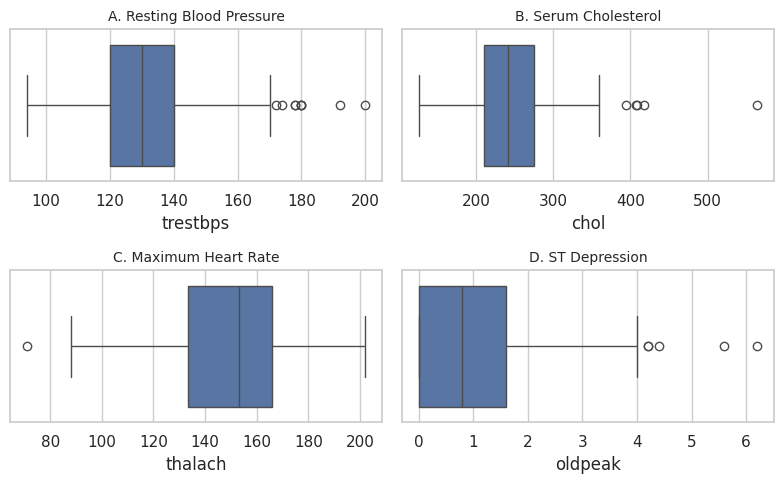

In [ ]:
selected_cols = ['trestbps', 'chol', 'thalach', 'oldpeak']

fig, ax = plt.subplots(2, 2, figsize=(8, 5))
ax = ax.flatten()

titles = ['A. Resting Blood Pressure', 'B. Serum Cholesterol','C. Maximum Heart Rate','D. ST Depression']

for i, col in enumerate(selected_cols):
    sns.boxplot(
        x=df[col], ax=ax[i],orient='h'
    )
    ax[i].set_title(titles[i], fontsize=10)
    ax[i].set_xlabel(col)

plt.tight_layout()

plt.show()

In [ ]:
# Check whether outlier rows correlate with the target (same logic as the ca/thal missingness check)
outlier_rows = is_outlier.any(axis=1)
print("Disease rate in outlier rows:    ", (df.loc[outlier_rows, "target"] > 0).mean().round(3))
print("Disease rate in non-outlier rows:", (df.loc[~outlier_rows, "target"] > 0).mean().round(3))

Disease rate in outlier rows:     0.684
Disease rate in non-outlier rows: 0.444


### c. Justify your choices (why impute vs. drop?).

Since only six values were missing across ca and thal, mode imputation was selected to preserve the sample size. Both variables were treated as categorical, making mode imputation a reasonable choice.

For the numerical outliers flagged by the IQR rule, I chose to keep them rather than drop or cap them. Checking whether outlier status correlates with the target showed outlier rows have a notably higher disease rate (68.4%) than non-outlier rows (44.4%). Removing them would both shrink an already small dataset and discard some of its most informative cases.

Instead, I will mitigate their influence on the scaled features via the log1p transform, which reduces the outsized effect of the tail without discarding the information.


## Train/Test Split

I split before imputing, log-transforming, standardizing, or one-hot encoding, and fit every one of those steps on the training set only, applying the learned statistics to the test set unchanged in order to avoid data leakage.

I did 80/20 stratified split, meaning 80% of patients are used for training and 20% for testing, while preserving the target distribution.

In [ ]:
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Training class counts:", y_train.value_counts().to_dict())
print("Testing class counts:", y_test.value_counts().to_dict())

Train: (242, 13) Test: (61, 13)
Training class counts: {0: 131, 1: 111}
Testing class counts: {0: 33, 1: 28}


Impute missing values using the mode computed from the training set only, then apply that same value to the test set (so that we do not recompute the mode on test).

In [ ]:
ca_mode = X_train["ca"].mode()[0]
thal_mode = X_train["thal"].mode()[0]

X_train["ca"] = X_train["ca"].fillna(ca_mode)
X_train["thal"] = X_train["thal"].fillna(thal_mode)

X_test["ca"] = X_test["ca"].fillna(ca_mode)
X_test["thal"] = X_test["thal"].fillna(thal_mode)

In [ ]:
desc = df[num_cols].describe().T
desc['skew'] = df[num_cols].skew()
desc['mean_vs_median_diff'] = desc['mean'] - desc['50%']
print(desc[['mean','50%','skew','mean_vs_median_diff']])

                mean    50%      skew  mean_vs_median_diff
age        54.438944   56.0 -0.209060            -1.561056
trestbps  131.689769  130.0  0.706035             1.689769
chol      246.693069  241.0  1.135503             5.693069
thalach   149.607261  153.0 -0.537449            -3.392739
oldpeak     1.039604    0.8  1.269720             0.239604


Age is genuinely close to symmetric (skew -0.2) But chol (skew 1.14) and especially oldpeak (skew 1.27) are strongly skewed.

The mean/median gap looked small for chol in absolute terms (246.7 vs 241) but that's misleading relative to the skew, because a few very large cholesterol values pull the mean up while most of the mass sits lower.

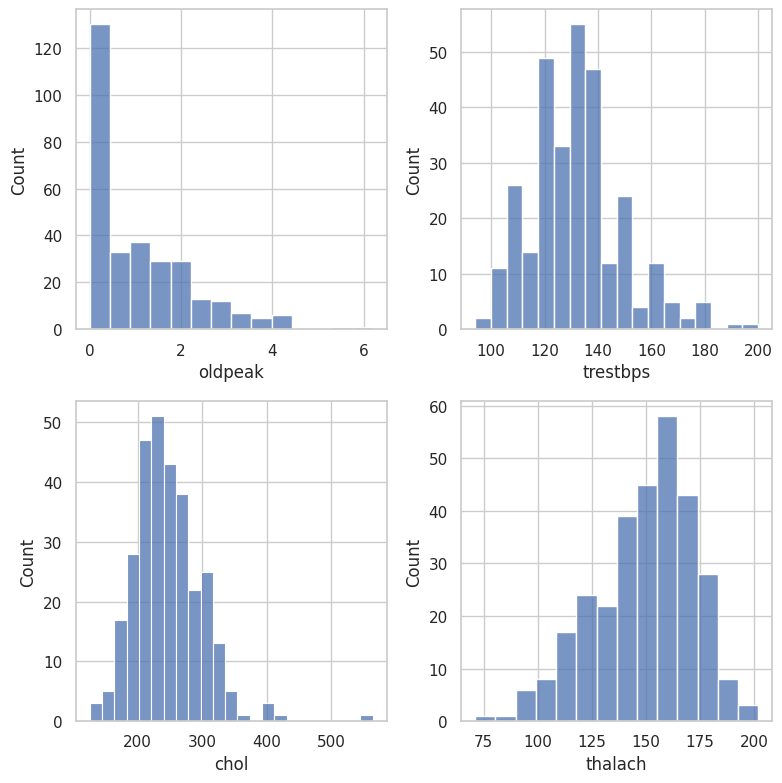

In [ ]:
# correlation check and scaling
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(8, 8))
sns.histplot(df["oldpeak"], ax=axes[0, 0])
sns.histplot(df["trestbps"], ax=axes[0, 1])
sns.histplot(df["chol"], ax=axes[1, 0])
sns.histplot(df["thalach"], ax=axes[1, 1])
plt.tight_layout()
plt.show()

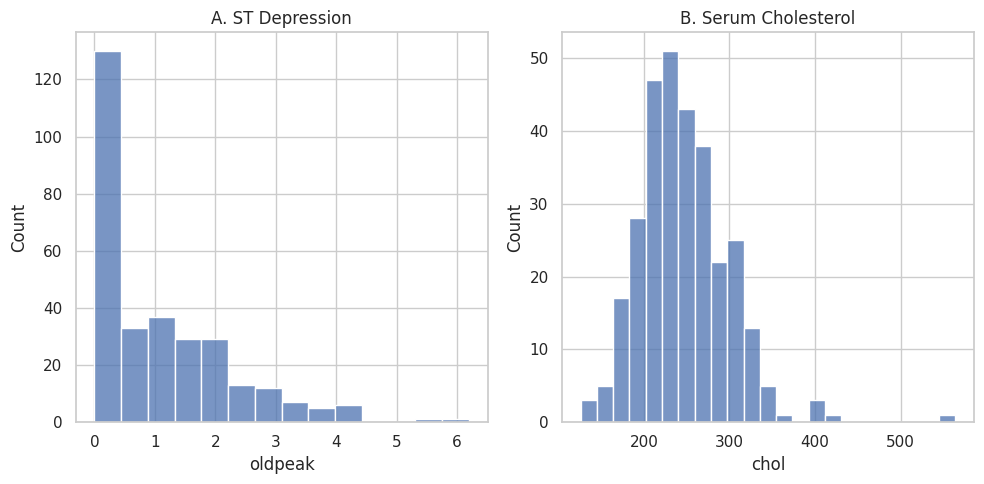

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))
sns.histplot(df["oldpeak"], ax=axes[0])
axes[0].set_title('A. ST Depression')
sns.histplot(df["chol"], ax=axes[1])
axes[1].set_title('B. Serum Cholesterol')
plt.tight_layout()
plt.show()

'chol' and 'oldpeak' should transforming using log-scale before standardizing due to the strong skewness.

# 2. Feature Engineering

### a. Apply appropriate transformations (normalization, standardization, log-scaling).



As shown in histograms, variables 'oldpeak' and 'chol' should undergo a log transformation to reduce skewness.


In [ ]:
for col in ["oldpeak", "chol"]:
    X_train[col] = np.log1p(X_train[col])
    X_test[col] = np.log1p(X_test[col])

Since continuous variables are measured in very different units and have substantially different scales, standardization is an appropriate transformation. Although StandardScaler does not eliminate the influence of outliers, it preserves their information without restricting the transformed values to a fixed range. For strongly right-skewed variables, log transformation was considered before standardization to reduce skewness.

The scaler is fit on the training set only and then used to transform both the training and test sets

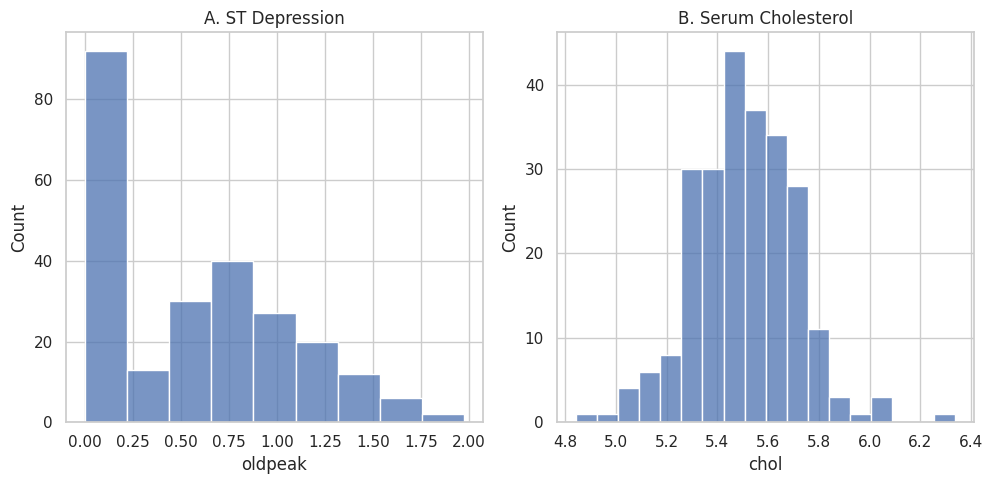

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))
sns.histplot(X_train["oldpeak"], ax=axes[0])
axes[0].set_title('A. ST Depression')
sns.histplot(X_train["chol"], ax=axes[1])
axes[1].set_title('B. Serum Cholesterol')
plt.tight_layout()
plt.show()

In [ ]:
#standardization
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

X_train.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
180,-0.729485,1.0,4.0,-0.395692,0.555767,0.0,2.0,0.708371,0.0,-0.301243,2.0,0.0,7.0
208,0.050166,1.0,2.0,-0.054513,0.335867,0.0,0.0,0.222495,0.0,-1.101983,1.0,0.0,3.0
167,-0.061212,0.0,2.0,0.059213,0.800500,1.0,2.0,0.399178,1.0,-1.101983,1.0,1.0,3.0
105,-0.061212,1.0,2.0,-1.305501,1.146220,0.0,0.0,0.266666,0.0,-1.101983,1.0,0.0,7.0
297,0.272924,0.0,4.0,0.514117,-0.074273,0.0,0.0,-1.190962,1.0,-0.741922,2.0,0.0,7.0


### b. Encode categorical variables (one-hot encoding or other methods).


In [ ]:
X_train = pd.get_dummies(X_train, columns=cat_cols, dtype=int, drop_first=True)
X_test = pd.get_dummies(X_test, columns=cat_cols, dtype=int)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

X_train.head()

,age,trestbps,chol,thalach,exang,oldpeak,sex_1.0,fbs_1.0,thal_6.0,thal_7.0,cp_2.0,cp_3.0,cp_4.0,restecg_1.0,restecg_2.0,slope_2.0,slope_3.0,ca_1.0,ca_2.0,ca_3.0
180,-0.729485,-0.395692,0.555767,0.708371,0.0,-0.301243,1,0,0,1,0,0,1,0,1,1,0,0,0,0
208,0.050166,-0.054513,0.335867,0.222495,0.0,-1.101983,1,0,0,0,1,0,0,0,0,0,0,0,0,0
167,-0.061212,0.059213,0.800500,0.399178,1.0,-1.101983,0,1,0,0,1,0,0,0,1,0,0,1,0,0
105,-0.061212,-1.305501,1.146220,0.266666,0.0,-1.101983,1,0,0,1,1,0,0,0,0,0,0,0,0,0
297,0.272924,0.514117,-0.074273,-1.190962,1.0,-0.741922,0,0,0,1,0,0,1,0,0,1,0,0,0,0


One category per variable was dropped as the reference level to avoid perfect multicollinearity with the intercept.

### c. Optionally, construct new features (e.g., ratios, group statistics).

Two interaction features were constructed to explore potential relationships between existing clinical predictors.


- I created an interaction between age and cholesterol. Because the relationship between cholesterol and heart disease may differ depending on age.

- I also created an interaction between exercise-induced angina and ST depression (exercise_risk) was constructed to examine whether the predictive relationship of ST depression differs depending on the presence of exercise-induced angina.

In [ ]:
for Xset in (X_train, X_test):
    Xset["age_chol"] = Xset["age"] * Xset["chol"]
    Xset["exercise_risk"] = Xset["exang"] * Xset["oldpeak"]

new_feat_cols = ["age_chol", "exercise_risk"]
X_train[new_feat_cols].describe()

,age_chol,exercise_risk
count,242.000000,242.000000
mean,0.219355,0.156032
std,1.050621,0.617183
min,-4.455309,-1.101983
25%,-0.222367,0.000000
50%,0.057533,-0.000000
75%,0.543876,0.000000
max,5.691941,2.624728


# 3. Model Training

### a. Naive Bayes classifier + Laplace smoothing (add-α).



GaussianNB was selected as a primary classifer. var_smoothing adds a small value to the estimated variances to improve numerical stability.

In [ ]:
gnb_results = {}
vars = [1e-9, 1e-3, 1e-2, 1e-1, 1.0]
for var in vars:
    gnb = GaussianNB(var_smoothing= var)
    gnb.fit(X_train, y_train)
    y_pred = gnb.predict(X_test)
    y_proba = gnb.predict_proba(X_test)[:, 1]
    gnb_results[var] = {
        "model" : gnb,
        "accuracy" : accuracy_score(y_test, y_pred),
        "confusion_matrix" : confusion_matrix(y_test, y_pred),
        "classification_report" : classification_report(y_test, y_pred),
        "y_proba": y_proba,
        "y_pred" : y_pred
    }

Since Bernoulli Naive Bayes assumes binary features, the continuous variables were converted into binary indicators using a threshold of zero after standardization.

In [ ]:
from sklearn.preprocessing import Binarizer

alphas = [1.0, 0.1, 0.01]
binarizer = Binarizer(threshold=0.0)
Xb_train = binarizer.fit_transform(X_train)
Xb_test = binarizer.transform(X_test)

bnb_results = {}
for alpha in alphas:
    bnb = BernoulliNB(alpha=alpha)
    bnb.fit(Xb_train, y_train)
    y_pred = bnb.predict(Xb_test)
    bnb_results[alpha] = {
        "model": bnb,
        "y_pred": y_pred,
        "y_proba": bnb.predict_proba(Xb_test)[:, 1],
        "accuracy": accuracy_score(y_test, y_pred),
    }


### b. Linear Regression model (Ridge / LASSO Regression)


In [ ]:
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred_lin_raw = lin_reg.predict(X_test)
y_pred_lin = (y_pred_lin_raw >= 0.5).astype(int)

ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
y_pred_ridge_raw = ridge.predict(X_test)
y_pred_ridge = (y_pred_ridge_raw >= 0.5).astype(int)

lasso = Lasso(alpha=0.01)
lasso.fit(X_train, y_train)
y_pred_lasso_raw = lasso.predict(X_test)
y_pred_lasso = (y_pred_lasso_raw >= 0.5).astype(int)

# 4. Model Evaluation

### a. Accuracy, Confusion Matrix, Precision/Recall/F1

In [ ]:
def evaluate(model_name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    conf_matrix = confusion_matrix(y_true, y_pred)
    class_report = classification_report(y_true, y_pred)
    return {
        "Model": model_name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "Confusion Matrix": conf_matrix,
        "Report": class_report
    }

results = []

# Evaluate the BernoulliNB models
for alpha in alphas:
    model = bnb_results[alpha]["model"]
    y_pred_nb = model.predict(Xb_test)
    results.append(evaluate(f"BernoulliNB (alpha={alpha})", y_test, y_pred_nb))

# Evaluate the GaussianNB models
for alpha in vars:
    model = gnb_results[alpha]["model"]
    y_pred_nb = model.predict(X_test)
    results.append(evaluate(f"GaussianNB (var_smoothing={alpha})", y_test, y_pred_nb))


# Evaluate the Linear, Ridge, and Lasso Regression models
for name, model in [("Linear Regression", lin_reg), ("Ridge Regression", ridge), ("Lasso Regression", lasso)]:
    y_pred_raw = model.predict(X_test)
    y_pred = (y_pred_raw >= 0.5).astype(int)
    results.append(evaluate(name, y_test, y_pred))

pd.DataFrame(results)[["Model", "Accuracy", "Precision", "Recall", "F1-Score"]]

,Model,Accuracy,Precision,Recall,F1-Score
0,BernoulliNB (alpha=1.0),0.918033,0.896552,0.928571,0.912281
1,BernoulliNB (alpha=0.1),0.918033,0.896552,0.928571,0.912281
2,BernoulliNB (alpha=0.01),0.901639,0.892857,0.892857,0.892857
3,GaussianNB (var_smoothing=1e-09),0.688525,0.609756,0.892857,0.724638
4,GaussianNB (var_smoothing=0.001),0.836066,0.800000,0.857143,0.827586
5,GaussianNB (var_smoothing=0.01),0.852459,0.806452,0.892857,0.847458
6,GaussianNB (var_smoothing=0.1),0.901639,0.866667,0.928571,0.896552
7,GaussianNB (var_smoothing=1.0),0.819672,0.869565,0.714286,0.784314
8,Linear Regression,0.901639,0.892857,0.892857,0.892857
9,Ridge Regression,0.901639,0.892857,0.892857,0.892857


Confusion matrices were generated for GaussianNB, BernoulliNB, Linear Regression, Ridge Regression, and LASSO Regression to compare their classification performance, including false positives and false negatives.

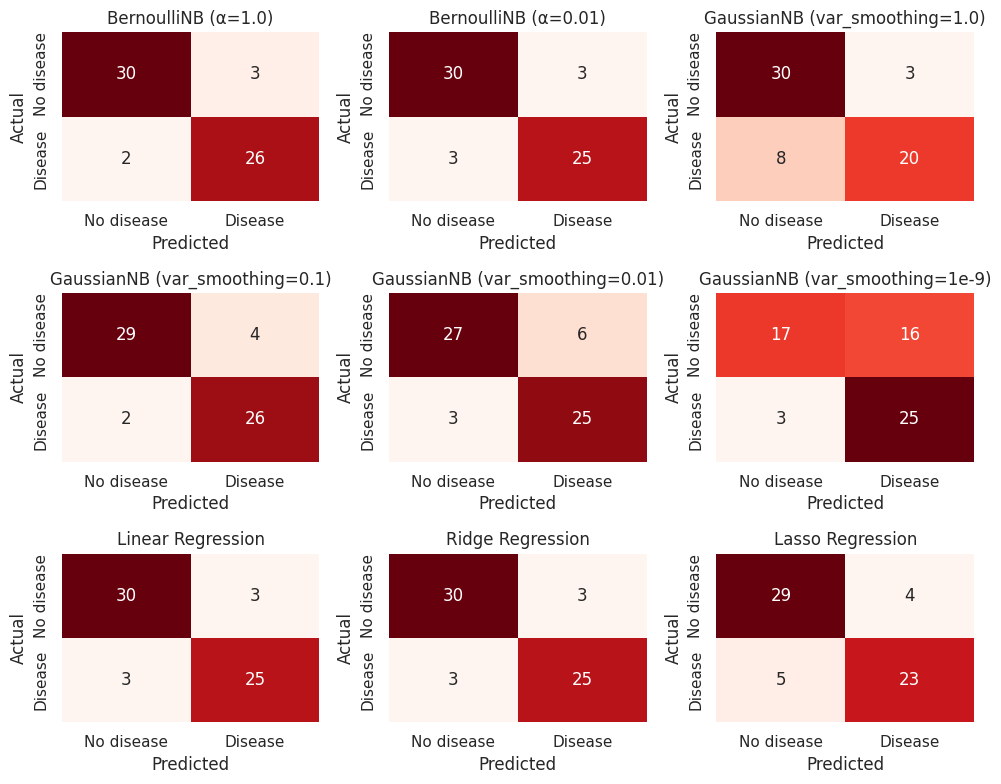

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(10, 8))
models_for_cm = [
    ("BernoulliNB (α=1.0)", bnb_results[1.0]["y_pred"]),
    ("BernoulliNB (α=0.01)", bnb_results[0.01]["y_pred"]),
    ("GaussianNB (var_smoothing=1.0)", gnb_results[1.0]["y_pred"]),
    ("GaussianNB (var_smoothing=0.1)", gnb_results[0.1]["y_pred"]),
    ("GaussianNB (var_smoothing=0.01)", gnb_results[0.01]["y_pred"]),
    ("GaussianNB (var_smoothing=1e-9)", gnb_results[1e-9]["y_pred"]),
    ("Linear Regression", y_pred_lin),
    ("Ridge Regression", y_pred_ridge),
    ("Lasso Regression", y_pred_lasso),
]

for ax, (name, preds) in zip(axes.flat, models_for_cm):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Reds", cbar=False, ax=ax,
                xticklabels=["No disease", "Disease"], yticklabels=["No disease", "Disease"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

### b. Smoothing comparison (alpha=1.0 vs alpha=0.01)

In [ ]:
print ("__GaussianNB__")
print(f"var_smoothing=1.0  -> accuracy {gnb_results[1.0]['accuracy']:.4f}")
print(f"var_smoothing=0.1  -> accuracy {gnb_results[0.1]['accuracy']:.4f}")
print(f"var_smoothing=0.01 -> accuracy {gnb_results[0.01]['accuracy']:.4f}")
print(f"var_smoothing=1e-9 -> accuracy {gnb_results[1e-9]['accuracy']:.4f}")


print ("__BernuoulliNB__")
print(f"alpha_smoothing=1.0  -> accuracy {bnb_results[1.0]['accuracy']:.4f}")
print(f"alpha_smoothing=0.1  -> accuracy {bnb_results[0.1]['accuracy']:.4f}")
print(f"alpha_smoothing=0.01 -> accuracy {bnb_results[0.01]['accuracy']:.4f}")


__GaussianNB__
var_smoothing=1.0  -> accuracy 0.8197
var_smoothing=0.1  -> accuracy 0.9016
var_smoothing=0.01 -> accuracy 0.8525
var_smoothing=1e-9 -> accuracy 0.6885
__BernuoulliNB__
alpha_smoothing=1.0  -> accuracy 0.9180
alpha_smoothing=0.1  -> accuracy 0.9180
alpha_smoothing=0.01 -> accuracy 0.9016


For BernoulliNB, α = 1.0 and α = 0.1 produced identical classification metrics, whereas α = 0.01 resulted in slightly lower accuracy and F1-score. This suggests that the additive smoothing affected classification performance on the test set. However, the identical metrics for α = 1.0 and α = 0.1 do not necessarily mean that they produced the exactly same probabilities.
For GaussianNB, changing var_smoothing also affected classification performance but there is no clear relationship between var_smoothing value and the accuracy. The highest accuracy was achieved with var_smoothing = 0.1, rather than the smallest or largest value. As var_smoothing is not equivalent to the Laplace smoothing in BernoulliNB, the effects of these two parameters are not directly comparable.


### c. ROC curves and AUC

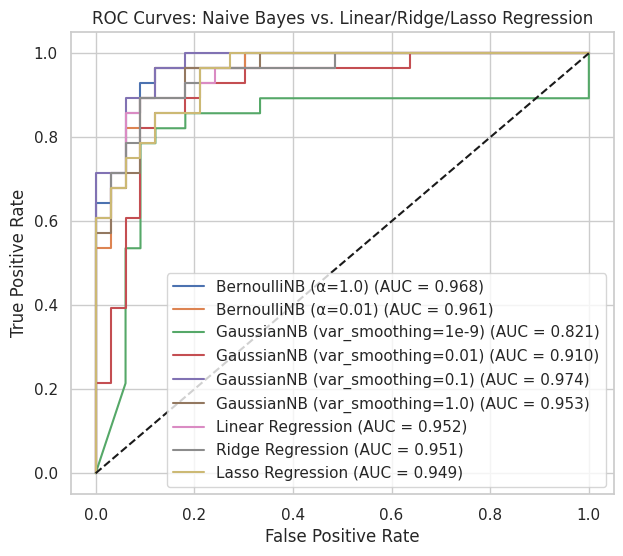

In [ ]:
plt.figure(figsize=(7, 6))

roc_models = {
    "BernoulliNB (α=1.0)" : bnb_results[1.0]["y_proba"],
    "BernoulliNB (α=0.01)" : bnb_results[0.01]["y_proba"],
    "GaussianNB (var_smoothing=1e-9)": gnb_results[1e-9]["y_proba"],
    "GaussianNB (var_smoothing=0.01)": gnb_results[0.01]["y_proba"],
    "GaussianNB (var_smoothing=0.1)": gnb_results[0.1]["y_proba"],
    "GaussianNB (var_smoothing=1.0)": gnb_results[1.0]["y_proba"],
    "Linear Regression": y_pred_lin_raw,
    "Ridge Regression": y_pred_ridge_raw,
    "Lasso Regression": y_pred_lasso_raw,
}

for name, scores in roc_models.items():
    fpr, tpr, thresholds = roc_curve(y_test, scores)
    auc_score = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.3f})")

plt.plot([0, 1], [0, 1], 'k--')
plt.title("ROC Curves: Naive Bayes vs. Linear/Ridge/Lasso Regression")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()
